In [1]:
import sys
sys.path.append("..")

import gc
import time
import numpy as np
import pandas as pd
import mlflow
from mlflow import MlflowClient
from src.datos import cargar_obt, agregar_features
from src.pipeline import (preparar_datos, configurar_mlflow, FEATURES, TARGET,
                          wape, costo_turnos, SEMILLA)

df = agregar_features(cargar_obt())
entrenamiento, prueba = preparar_datos(df)
del df
gc.collect()

configurar_mlflow()
client = MlflowClient()
print("Entrenamiento:", entrenamiento.shape, "| Prueba:", prueba.shape)

Entrenamiento: (757018, 59) | Prueba: (40282, 59)


In [2]:
mejores = mlflow.search_runs(
    experiment_names=["rossmann"],
    filter_string="tags.fase = 'tuning' and attributes.run_name LIKE '%_mejor' and attributes.status = 'FINISHED'",
)
columnas = {
    "tags.mlflow.runName": "corrida", "tags.familia": "familia",
    "metrics.wape_train": "wape_train", "metrics.wape_cv_media": "wape_cv",
    "metrics.wape_cv_std": "wape_cv_std", "metrics.costo_cv_media": "costo_cv",
    "metrics.segundos_entrenamiento": "segundos_entrenamiento",
}
tabla = mejores[["run_id", *columnas]].rename(columns=columnas).sort_values("wape_cv").reset_index(drop=True)
tabla.round(4)

,run_id,corrida,familia,wape_train,wape_cv,wape_cv_std,costo_cv,segundos_entrenamiento
0,2e9af5153c03402aa4e0f653be8d90bf,tuning_random_forest_mejor,bagging,0.0771,0.0867,0.0040,0.1383,65.4527
1,d6e81855a4cc42c9b9219b99d7e44a41,tuning_hgb_mejor,boosting,0.0771,0.0869,0.0038,0.1349,58.6379
2,1e4fb34a0ab64a1ea4d78c232d021b9a,tuning_mlp_mejor,red_neuronal,0.0857,0.0904,0.0045,0.1381,700.8955


In [3]:
from src.pipeline import ReglaNegocio

id_hgb = tabla.loc[tabla["corrida"] == "tuning_hgb_mejor", "run_id"].item()
id_rf = tabla.loc[tabla["corrida"] == "tuning_random_forest_mejor", "run_id"].item()
modelos = {
    "HistGradientBoosting": mlflow.sklearn.load_model(f"runs:/{id_hgb}/modelo"),
    "Random Forest": mlflow.sklearn.load_model(f"runs:/{id_rf}/modelo"),
    "Regla de negocio": ReglaNegocio().fit(entrenamiento[FEATURES], entrenamiento[TARGET]),
}

X_prueba, y_prueba = prueba[FEATURES], prueba[TARGET]
preds, filas = {}, []
for nombre, modelo in modelos.items():
    inicio = time.time()
    preds[nombre] = modelo.predict(X_prueba)
    segundos = time.time() - inicio
    fila = {"modelo": nombre, "wape_prueba": wape(y_prueba, preds[nombre])}
    for k in [0.5, 1, 2, 3]:
        fila[f"costo_k{k}"] = costo_turnos(y_prueba, preds[nombre], k)
    fila["segundos_inferencia"] = segundos
    filas.append(fila)

res_prueba = pd.DataFrame(filas).set_index("modelo").round(4)
res_prueba

,wape_prueba,costo_k0.5,costo_k1,costo_k2,costo_k3,segundos_inferencia
modelo,,,,,,
HistGradientBoosting,0.0902,0.0722,0.0902,0.1262,0.1622,1.7757
Random Forest,0.0956,0.0787,0.0956,0.1292,0.1629,2.2157
Regla de negocio,0.1801,0.1503,0.1801,0.2396,0.2991,0.0097


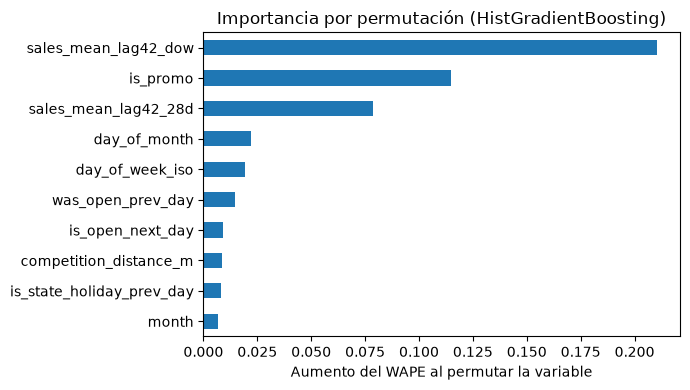

,aumento_wape,desviacion
sales_mean_lag42_dow,0.2105,0.0020
is_promo,0.1149,0.0020
sales_mean_lag42_28d,0.0788,0.0011
day_of_month,0.0222,0.0005
day_of_week_iso,0.0191,0.0004
was_open_prev_day,0.0145,0.0005
is_open_next_day,0.0090,0.0004
competition_distance_m,0.0086,0.0003
is_state_holiday_prev_day,0.0081,0.0001
month,0.0065,0.0001


In [4]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from src.pipeline import wape_scorer

# Muestra del último bloque de validación (no de la prueba, que ya se usó)
validacion = entrenamiento[entrenamiento["sales_date"] >= "2015-05-09"].sample(5000, random_state=SEMILLA)
imp = permutation_importance(
    modelos["HistGradientBoosting"], validacion[FEATURES], validacion[TARGET],
    scoring=wape_scorer, n_repeats=5, random_state=SEMILLA,
)
importancia = (pd.DataFrame({"aumento_wape": imp.importances_mean, "desviacion": imp.importances_std},
                            index=FEATURES)
               .sort_values("aumento_wape", ascending=False))

importancia.head(10).iloc[::-1]["aumento_wape"].plot.barh(figsize=(7, 4))
plt.xlabel("Aumento del WAPE al permutar la variable")
plt.title("Importancia por permutación (HistGradientBoosting)")
plt.tight_layout()
plt.show()

importancia.head(10).round(4)

In [5]:
from mlflow.models import infer_signature
from src.pipeline import commit_git, hash_datos, TABLA_ORIGEN, TIPOS_CONFIABLES

ganador = modelos["HistGradientBoosting"]
pred_ganador = ganador.predict(X_prueba)
ejemplo = X_prueba.head(5)

with mlflow.start_run(run_name="final_hgb_champion") as corrida_final:
    mlflow.log_params({
        **{f"modelo__{k}": v for k, v in ganador.named_steps["modelo"].get_params().items()},
        "origen_run_id": id_hgb, "semilla": SEMILLA, "datos_tabla": TABLA_ORIGEN,
        "datos_prueba": "2015-06-20 a 2015-07-31", "datos_hash_prueba": hash_datos(X_prueba, y_prueba),
    })
    mlflow.log_metrics({
        "wape_prueba": wape(y_prueba, pred_ganador),
        **{f"costo_prueba_k{k}": costo_turnos(y_prueba, pred_ganador, k) for k in [0.5, 1, 2, 3]},
        "segundos_inferencia": res_prueba.loc["HistGradientBoosting", "segundos_inferencia"],
        "wape_prueba_challenger": wape(y_prueba, preds["Random Forest"]),
        "wape_prueba_regla_negocio": wape(y_prueba, preds["Regla de negocio"]),
    })
    mlflow.set_tags({"fase": "final", "familia": "boosting", "git_commit": commit_git()})
    info = mlflow.sklearn.log_model(
        ganador, name="modelo", signature=infer_signature(ejemplo, ganador.predict(ejemplo)),
        input_example=ejemplo, skops_trusted_types=TIPOS_CONFIABLES,
        registered_model_name="rossmann-modelo",
    )

version_champion = info.registered_model_version
version_challenger = mlflow.register_model(f"runs:/{id_rf}/modelo", "rossmann-modelo").version
client.set_registered_model_alias("rossmann-modelo", "champion", version_champion)
client.set_registered_model_alias("rossmann-modelo", "challenger", version_challenger)

print("run_id final:", corrida_final.info.run_id)
print("champion: versión", version_champion, "| challenger: versión", version_challenger)
print("WAPE de prueba registrado:", wape(y_prueba, pred_ganador))

c:\Users\pc\Desktop\pset_3\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Successfully registered model 'rossmann-modelo'.
2026/11/18 15:54:44 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: rossmann-modelo, version 1
Created version '1' of model 'rossmann-modelo'.


🏃 View run final_hgb_champion at: http://localhost:5000/#/experiments/1/runs/0e34d952530740ec900db92ec5831a15
🧪 View experiment at: http://localhost:5000/#/experiments/1


Registered model 'rossmann-modelo' already exists. Creating a new version of this model...
2026/11/18 15:54:45 WARNING mlflow.tracking._model_registry.fluent: Run with id 2e9af5153c03402aa4e0f653be8d90bf has no artifacts at artifact path 'modelo', registering model based on models:/m-ae413d55a86f494ead40ac0b623fe12e instead
2026/11/18 15:54:45 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: rossmann-modelo, version 2
Created version '2' of model 'rossmann-modelo'.


run_id final: 0e34d952530740ec900db92ec5831a15
champion: versión 1 | challenger: versión 2
WAPE de prueba registrado: 0.09023300468244734
